In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import h5py
import math
import cv2
import torch
from snntorch import spikegen
import os
from skimage import transform
from lightglue import viz2d
from lightglue import LightGlue, SuperPoint, DISK
from lightglue.utils import numpy_image_to_torch, rbd
from pathlib import Path
from ultralytics import YOLO
import matplotlib.patches as patches

### Select candidate frames for homography

In [4]:
def spatial_entropy(frame, grid=(3, 4), normalize=True):
    frame = np.asarray(frame)
    h, w = frame.shape
    gh, gw = grid

    ys = np.linspace(0, h, gh + 1, dtype=int)
    xs = np.linspace(0, w, gw + 1, dtype=int)

    # sum activity in each cell
    cell_counts = []
    for i in range(gh):
        for j in range(gw):
            cell = frame[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            cell_counts.append(cell.sum())

    cell_counts = np.asarray(cell_counts, dtype=float)
    total = cell_counts.sum()

    if total == 0:
        return 0.0, cell_counts

    # probability distribution over cells
    p = cell_counts / total
    p = p[p > 0]  # avoid log(0)

    H = -(p * np.log2(p)).sum()

    if normalize:
        H_max = np.log2(gh * gw)
        H = H / H_max if H_max > 0 else 0.0

    return float(H), cell_counts

In [ ]:
clip_dir = "//172.16.222.2/tmp/Nora/traffic_flow_data/week_36/box_3/2024_09_10_15_50_59_recordings/event_frames"
clip_path= os.path.join(clip_dir, "event_clip_000_frames.h5")

with h5py.File(clip_path, "r") as f:
    frames = f["frames"][:]

activity = frames.reshape(frames.shape[0], -1).sum(axis=1)

In [57]:
candidates = []

for i in range(len(frames)):
    a = activity[i]/frames[0].size
    if  a > 0.05 and a < 0.4:
        entropy, counts = spatial_entropy(frames[i], (3, 4))
        if entropy > 0.85 and entropy < 0.96:
            candidates.append({"frame": frames[i], "idx": i, "activity": a, "entropy": entropy})

print(f"Found {len(candidates)} candidate frames")

Found 347 candidate frames


In [ ]:
# Search for clip
found_candidates = 0
clip_idx = 1

while found_candidates < 100:
    clip_path = os.path.join(clip_dir, f"event_clip_{clip_idx:03d}_frames.h5")

    with h5py.File(clip_path, "r") as f:
        frames = f["frames"][:]

    activity = frames.reshape(frames.shape[0], -1).sum(axis=1)

    candidates = []

    for i in range(len(frames)):
        a = activity[i]/frames[0].size
        if  a > 0.05 and a < 0.4:
            entropy, counts = spatial_entropy(frames[i], (3, 4))
            if entropy > 0.85:
                candidates.append({"frame": frames[i], "idx": i, "activity": a, "entropy": entropy})

    print(f"Found {len(candidates)} candidate frames in clip_{clip_idx:03d}")
    found_candidates = len(candidates)
    clip_idx += 1

Found 44 candidate frames in clip_001
Found 0 candidate frames in clip_002
Found 0 candidate frames in clip_003
Found 2 candidate frames in clip_004
Found 1 candidate frames in clip_005
Found 0 candidate frames in clip_006


KeyboardInterrupt: 

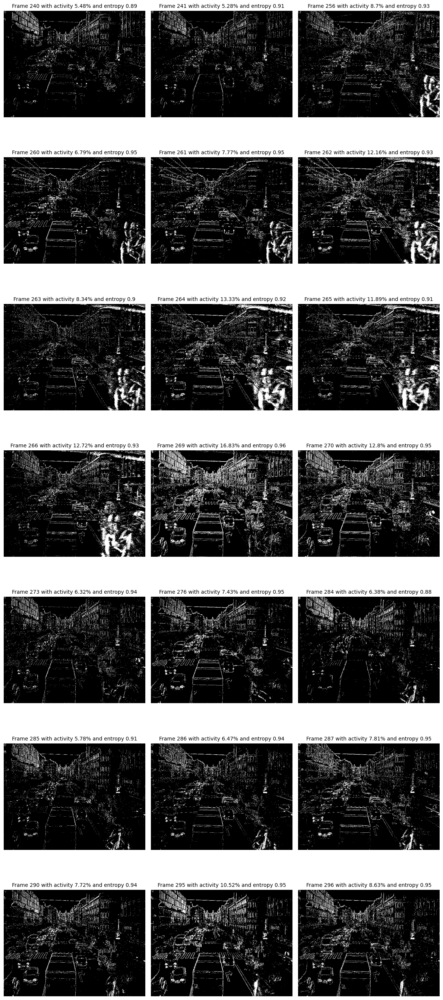

In [58]:
n = len(candidates)
cols = 3
n = np.min((21,n))
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(rows * cols):
    ax = axes[i]

    if i < n:
        fm = candidates[i]
        ax.imshow(fm["frame"], cmap='gray')
        ax.set_title(f"Frame {fm['idx']} with activity {round(fm['activity']*100,2)}% and entropy {round(fm['entropy'],2)}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [59]:
k = 10

top_candidates = sorted(candidates, key=lambda x: x["activity"], reverse=True)[:10]
top_indices = [c["idx"] for c in top_candidates]
top_activity = [c["activity"] for c in top_candidates]
top_frames = [c["frame"] for c in top_candidates]

In [60]:
c = 1
for i in range(len(top_candidates)):
    entropy, counts = spatial_entropy(top_frames[i], (16, 16))
    print(f"{c}. Activity: {round(counts.sum()/top_frames[i].size*100, 2)}%, Entropy: {round(entropy,3)}, Frame nbr: {top_indices[i]}")
    c += 1

1. Activity: 25.59%, Entropy: 0.945, Frame nbr: 751
2. Activity: 24.75%, Entropy: 0.941, Frame nbr: 754
3. Activity: 22.71%, Entropy: 0.936, Frame nbr: 963
4. Activity: 22.25%, Entropy: 0.941, Frame nbr: 961
5. Activity: 20.84%, Entropy: 0.943, Frame nbr: 955
6. Activity: 20.29%, Entropy: 0.943, Frame nbr: 766
7. Activity: 19.97%, Entropy: 0.929, Frame nbr: 764
8. Activity: 19.35%, Entropy: 0.944, Frame nbr: 760
9. Activity: 19.1%, Entropy: 0.935, Frame nbr: 954
10. Activity: 18.61%, Entropy: 0.937, Frame nbr: 960


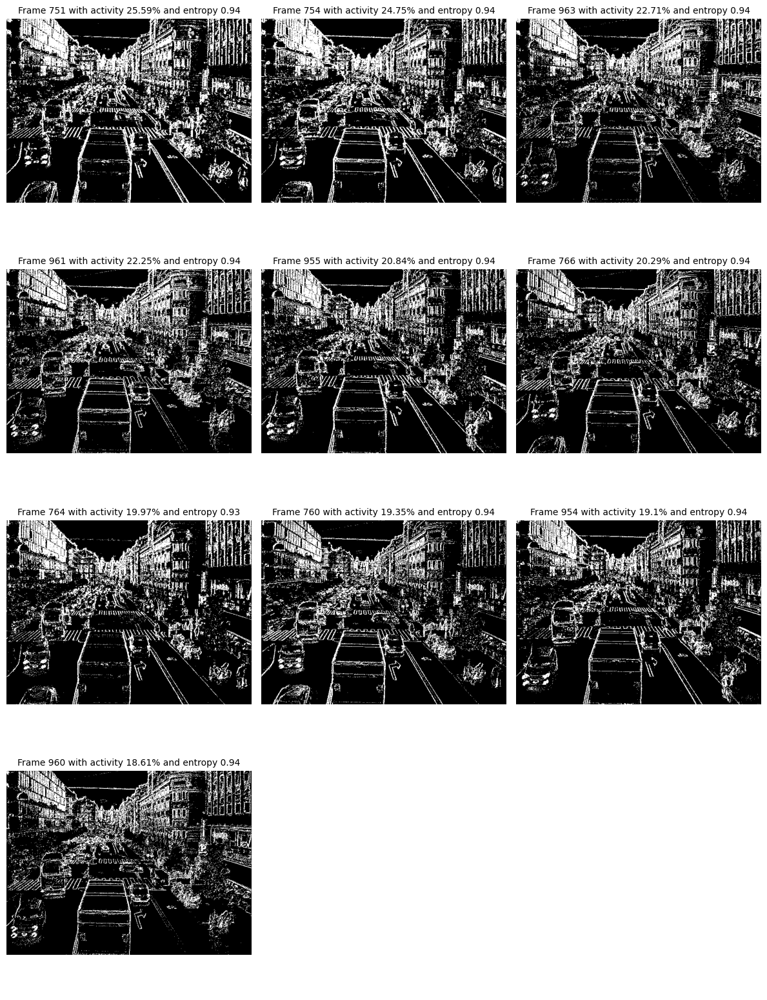

In [61]:
n = len(top_indices)
cols = 3
n = np.min((21,n))
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(rows * cols):
    ax = axes[i]

    if i < n:
        entropy, counts = spatial_entropy(top_frames[i], (16, 16))
        ax.imshow(top_frames[i], cmap='gray')
        ax.set_title(f"Frame {top_indices[i]} with activity {round(counts.sum()/frames[0].size*100, 2)}% and entropy {round(entropy,2)}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

### Test build homography for evaluation

In [64]:
video_path = "//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_36/box3/2024_09_10_15_50_59_recordings/video.avi"
timestamp_path = "//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_36/box3/2024_09_10_15_50_59_recordings/timestamps.csv"
out_path = "week_36/box_3/2024_09_10_15_50_59_recordings/homography.npz"

In [65]:
df_timestamps = pd.read_csv(timestamp_path)
SHIFT = df_timestamps.index[df_timestamps["event_time"] != 0][0]

In [66]:
cfg = {
    "extractor": "SuperPoint",
    "device": "cpu",   # change to "cuda" if available
    "max_kpts": 4096,
    "homography": {
        "method": cv2.RANSAC,
        "ransacReprojThreshold": 3.0,
    }
}

In [67]:
def extract_clip_id(filename: str):
    # Extract clip id like 'clip_000' from filename
    m = re.search(r"(clip_\d{3})", filename)
    return m.group(1) if m else None


def event_to_gray_uint8(img):
    img = np.asarray(img, np.float32)
    img -= img.min()
    mx = img.max()
    if mx > 0:
        img *= 255.0 / mx
    return img.astype(np.uint8)


def load_frame(path: str):
    ext = os.path.splitext(path)[1].lower()

    if ext == ".npy":
        return np.load(path)

    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise RuntimeError(f"Could not read file: {path}")

    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    return img


def preprocess_lightglue(img):
    img = event_to_gray_uint8(img)
    return numpy_image_to_torch(img)


def build_lightglue_models(cfg):
    device = cfg["device"]

    if cfg["extractor"] == "SuperPoint":
        extractor = SuperPoint(max_num_keypoints=cfg["max_kpts"]).eval().to(device)
        matcher = LightGlue(features="superpoint").eval().to(device)
    elif cfg["extractor"] == "DISK":
        extractor = DISK(max_num_keypoints=cfg["max_kpts"]).eval().to(device)
        matcher = LightGlue(features="disk").eval().to(device)
    else:
        raise ValueError(f"Unknown extractor: {cfg['extractor']}")

    return extractor, matcher


@torch.inference_mode()
def match_lightglue(img0, img1, extractor, matcher, device="cpu"):
    img0 = preprocess_lightglue(img0).to(device)
    img1 = preprocess_lightglue(img1).to(device)

    feats0 = extractor.extract(img0)
    feats1 = extractor.extract(img1)

    matches01 = matcher({"image0": feats0, "image1": feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]

    kpts0 = feats0["keypoints"]
    kpts1 = feats1["keypoints"]
    matches = matches01["matches"]

    points0 = kpts0[matches[:, 0]]
    points1 = kpts1[matches[:, 1]]

    return {
        "points0": points0,
        "points1": points1,
        "matches": matches,
        "kpts0": kpts0,
        "kpts1": kpts1,
        "matches01": matches01,
    }

def visualize_lightglue(img0, img1, points0, points1, kpts0, kpts1, matches01, **kwargs):
    axes = viz2d.plot_images([img0, img1])
    viz2d.plot_matches(points0, points1, color='lime', lw=0.2)
    viz2d.add_text(0, f'Stop after {matches01["stop"]} layers', fs=20)

    kpc0, kpc1 = viz2d.cm_prune(matches01['prune0']), viz2d.cm_prune(matches01['prune1'])
    viz2d.plot_images([img0, img1])
    viz2d.plot_keypoints([kpts0, kpts1], colors=[kpc0, kpc1], ps=10)


def homography_from_matches(results, cfg):
    pts0 = results["points0"]
    pts1 = results["points1"]

    if torch.is_tensor(pts0):
        pts0 = pts0.detach().cpu().numpy()
    if torch.is_tensor(pts1):
        pts1 = pts1.detach().cpu().numpy()

    pts0 = np.asarray(pts0, dtype=np.float32).reshape(-1, 2)
    pts1 = np.asarray(pts1, dtype=np.float32).reshape(-1, 2)

    if len(pts0) < 4:
        return None, None, pts0, pts1

    H, mask = cv2.findHomography(
        pts0,
        pts1,
        method=cfg["homography"]["method"],
        ransacReprojThreshold=cfg["homography"]["ransacReprojThreshold"],
    )
    return H, mask, pts0, pts1

def collect_pairs_by_clip(proxy_dir, event_dir):
    proxy_by_clip = {}
    event_by_clip = {}

    for f in os.listdir(proxy_dir):
        full = os.path.join(proxy_dir, f)
        if not os.path.isfile(full):
            continue
        clip_id = extract_clip_id(f)
        if clip_id is None:
            continue
        proxy_by_clip.setdefault(clip_id, []).append(full)

    for f in os.listdir(event_dir):
        full = os.path.join(event_dir, f)
        if not os.path.isfile(full):
            continue
        clip_id = extract_clip_id(f)
        if clip_id is None:
            continue
        event_by_clip.setdefault(clip_id, []).append(full)

    common_clips = sorted(
        set(proxy_by_clip.keys()) & set(event_by_clip.keys()),
        key=lambda x: int(re.search(r"\d+", x).group())
    )

    pairs = []
    for clip_id in common_clips:
        proxy_files = sorted(proxy_by_clip[clip_id])
        event_files = sorted(event_by_clip[clip_id])

        if len(proxy_files) != 1:
            print(f"Skipping {clip_id}: expected 1 proxy frame, found {len(proxy_files)}")
            continue

        if len(event_files) != 1:
            print(f"Skipping {clip_id}: expected 1 extracted event frame, found {len(event_files)}")
            continue

        pairs.append((clip_id, proxy_files[0], event_files[0]))

    return pairs

In [68]:
candidate_idx = [candidate["idx"] for candidate in candidates]

In [69]:
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

top_set = set(int(i) for i in candidate_idx)

spike_dict = {}
counter = 0

ret, frame = cap.read()
if not ret:
    raise RuntimeError("Empty video")

prev_gray = None
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

t = 0

while t < (SHIFT):
    ret, frame = cap.read()
    t += 1

i = 0

while True:
    ret, next_frame = cap.read()
    if not ret:
        break

    next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

    if i in top_set:

        if prev_gray is None:
            counter += 1
        else:
            data = torch.from_numpy(
                np.stack([prev_gray, gray, next_gray], axis=0)
            ).to(torch.float32)

            spikes = spikegen.delta(data, threshold=8)
            sp = spikes[1:].cpu().numpy() if torch.is_tensor(spikes) else spikes

            spike_dict[i] = (sp > 0).any(axis=0).astype(np.uint8)
        
        counter += 1

        if counter == len(top_set):
            break

    # Shift window forward
    prev_gray = gray
    gray = next_gray
    frame = next_frame
    i += 1

cap.release()

In [70]:
extractor, matcher = build_lightglue_models(cfg)

In [16]:
Hs = []

In [19]:
for idx in candidate_idx:
    print(f"Processing {idx}")

    proxy_img = event_to_gray_uint8(spike_dict[idx])
    event_img = event_to_gray_uint8(frames[idx])

    results = match_lightglue(
        proxy_img,
        event_img,
        extractor=extractor,
        matcher=matcher,
        device=cfg["device"],
    )

    H, mask, pts0, pts1 = homography_from_matches(results, cfg)

    Hs.append(H)

    print(f"matches={len(results['matches'])}, out of total features={results['kpts1'].shape[0]}")

Processing 601
matches=796, out of total features=2626
Processing 608
matches=833, out of total features=3057
Processing 609
matches=902, out of total features=3198
Processing 610
matches=879, out of total features=3042
Processing 611
matches=847, out of total features=3064
Processing 619
matches=910, out of total features=3027
Processing 623
matches=773, out of total features=2840
Processing 624
matches=891, out of total features=2995
Processing 630
matches=1007, out of total features=3074
Processing 631
matches=1097, out of total features=3177
Processing 632
matches=1104, out of total features=3078
Processing 633
matches=1133, out of total features=3074
Processing 634
matches=1153, out of total features=3182
Processing 635
matches=1171, out of total features=3083
Processing 636
matches=1211, out of total features=3241
Processing 637
matches=1279, out of total features=3232
Processing 638
matches=1210, out of total features=3087
Processing 639
matches=1257, out of total features=3280


In [71]:
H_top = []
H_sel = []

In [72]:
for idx in top_indices:
    print(f"Processing {idx}")

    proxy_img = event_to_gray_uint8(spike_dict[idx])
    event_img = event_to_gray_uint8(frames[idx])

    results = match_lightglue(
        proxy_img,
        event_img,
        extractor=extractor,
        matcher=matcher,
        device=cfg["device"],
    )

    H, mask, pts0, pts1 = homography_from_matches(results, cfg)
    num_matches = len(pts0)
    num_inliers = 0 if mask is None else int(mask.ravel().sum())
    print(f"Num inliers: {num_inliers}")

    H_top.append(H)
    if num_inliers > 1000:
        H_sel.append(H)

    print(f"matches={len(results['matches'])}, out of total features={results['kpts1'].shape[0]}")

Processing 751
Num inliers: 943
matches=1473, out of total features=3251
Processing 754
Num inliers: 978
matches=1412, out of total features=3116
Processing 963
Num inliers: 877
matches=1418, out of total features=3269
Processing 961
Num inliers: 904
matches=1419, out of total features=3159
Processing 955
Num inliers: 933
matches=1441, out of total features=3181
Processing 766
Num inliers: 1042
matches=1496, out of total features=3371
Processing 764
Num inliers: 974
matches=1479, out of total features=3171
Processing 760
Num inliers: 1050
matches=1515, out of total features=3288
Processing 954
Num inliers: 997
matches=1460, out of total features=3129
Processing 960
Num inliers: 947
matches=1433, out of total features=3181


Processing 637
matches=1279, out of total features=3232
ref_idx = 15

In [ ]:
ref_idx = 15

# load first event frame
H2, W2 = spike_dict[601].shape[-2], spike_dict[601].shape[-1]
H1, W1 = frames[0].shape[-2], frames[0].shape[-1]

all_corner_dists = []   # every corner from every label
label_stats = []        # optional detailed storage
dists = []

for i in range(5400):
    frame_label_path = Path(f"//172.16.222.2/tmp/Nora/traffic_flow_data/week_36/box_3/2024_09_10_15_50_59_recordings/labels/clip_000/{i}.txt")
    for s in frame_label_path.read_text().splitlines():
        cls, x, y, w, h, conf = s.split()[:6]
        conf = float(conf)

        if conf <= 0.6:
            continue

        x, y, w, h = map(float, (x, y, w, h))

        # YOLO normalized -> pixel corners in spike image coordinates
        x *= W2
        y *= H2
        w *= W2
        h *= H2

        corners = np.float32([
            [x - w/2, y - h/2],  # top-left
            [x + w/2, y - h/2],  # top-right
            [x + w/2, y + h/2],  # bottom-right
            [x - w/2, y + h/2],  # bottom-left
        ]).reshape(-1, 1, 2)


        cs = []

        for h in Hs:
            c = cv2.perspectiveTransform(corners, h).reshape(-1, 2)
            cs.append(c)

        c_ref = cs[ref_idx]
        frame_dists = []

        for c in cs:
            corner_dists = np.abs(c_ref - c).sum(axis=1)
            dists.append(corner_dists.mean())
            frame_dists.append(corner_dists.mean()) 

        label_stats.append({
            "class": cls,
            "conf": conf,
            "mean_dist": np.array(frame_dists).mean(),
            "std_dist": np.array(frame_dists).std(),
        })


AttributeError: 'list' object has no attribute 'mean'

In [36]:
# Overall stats
overall_mean = np.array(dists).mean()
overall_std = np.array(dists).std()

print(f"Overall corner Manhattan distance: mean={overall_mean:.3f}, std={overall_std:.3f}")

# Optional: inspect each label
for i, st in enumerate(label_stats):
    print(
        f"label {i}: class={st['class']}, conf={st['conf']:.2f}, "
        f"mean={st['mean_dist']:.3f}, std={st['std_dist']:.3f}"
    )

Overall corner Manhattan distance: mean=7.205, std=6.851
label 0: class=2, conf=0.92, mean=11.092, std=7.046
label 1: class=2, conf=0.87, mean=2.488, std=1.331
label 2: class=0, conf=0.81, mean=16.656, std=7.513
label 3: class=1, conf=0.75, mean=9.323, std=5.576
label 4: class=7, conf=0.74, mean=7.357, std=3.557
label 5: class=0, conf=0.69, mean=11.267, std=5.428
label 6: class=7, conf=0.67, mean=3.863, std=1.988
label 7: class=74, conf=0.62, mean=2.258, std=1.576
label 8: class=2, conf=0.92, mean=11.084, std=7.039
label 9: class=2, conf=0.83, mean=2.490, std=1.329
label 10: class=0, conf=0.85, mean=16.576, std=7.476
label 11: class=1, conf=0.63, mean=9.291, std=5.569
label 12: class=7, conf=0.75, mean=7.361, std=3.557
label 13: class=0, conf=0.63, mean=11.239, std=5.414
label 14: class=7, conf=0.70, mean=3.855, std=1.985
label 15: class=2, conf=0.62, mean=2.533, std=1.405
label 16: class=2, conf=0.87, mean=7.340, std=4.575
label 17: class=0, conf=0.60, mean=8.232, std=4.593
label 18: 

In [101]:
ref_idx = 5
pad = 50

def box_inside_frame(corners_xy, W, H, pad=10):
    """
    corners_xy shape: (4, 2)
    """
    xs = corners_xy[:, 0]
    ys = corners_xy[:, 1]

    return (
        (xs >= pad).all() and
        (xs <= W - pad).all() and
        (ys >= pad).all() and
        (ys <= H - pad).all()
    )

# load first event frame
H2, W2 = spike_dict[601].shape[-2], spike_dict[601].shape[-1]
H1, W1 = frames[0].shape[-2], frames[0].shape[-1]

all_corner_dists = []   # every corner from every label
label_stats = []        # optional detailed storage
dists = []

for i in range(5400):
    frame_label_path = Path(f"//172.16.222.2/tmp/Nora/traffic_flow_data/week_36/box_3/2024_09_10_15_50_59_recordings/labels/clip_000/{i}.txt")
    for s in frame_label_path.read_text().splitlines():
        cls, x, y, w, h, conf = s.split()[:6]
        conf = float(conf)

        if conf <= 0.6:
            continue

        x, y, w, h = map(float, (x, y, w, h))

        # YOLO normalized -> pixel corners in spike image coordinates
        x *= W2
        y *= H2
        w *= W2
        h *= H2

        corners = np.float32([
            [x - w/2, y - h/2],  # top-left
            [x + w/2, y - h/2],  # top-right
            [x + w/2, y + h/2],  # bottom-right
            [x - w/2, y + h/2],  # bottom-left
        ]).reshape(-1, 1, 2)


        cs = []

        for h in H_top:
            c = cv2.perspectiveTransform(corners, h).reshape(-1, 2)
            cs.append(c)

        inside_all_homographies = all(
            box_inside_frame(c, W1, H1, pad=pad)
            for c in cs
        )

        if not inside_all_homographies:
            continue

        c_ref = cs[ref_idx]
        frame_dists = []

        for c in cs:
            corner_dists = np.abs(c_ref - c).sum(axis=1)
            dists.append(corner_dists.mean())
            frame_dists.append(corner_dists.mean()) 

        label_stats.append({
            "class": cls,
            "conf": conf,
            "mean_dist": np.array(frame_dists).mean(),
            "std_dist": np.array(frame_dists).std(),
        })


In [102]:
# Overall stats
overall_mean = np.array(dists).mean()
overall_std = np.array(dists).std()

print(f"Overall corner Manhattan distance: mean={overall_mean:.3f}, std={overall_std:.3f}")

# Optional: inspect each label
for i, st in enumerate(label_stats):
    print(
        f"label {i}: class={st['class']}, conf={st['conf']:.2f}, "
        f"mean={st['mean_dist']:.3f}, std={st['std_dist']:.3f}"
    )

Overall corner Manhattan distance: mean=2.444, std=1.802
label 0: class=2, conf=0.87, mean=1.926, std=1.421
label 1: class=7, conf=0.67, mean=2.038, std=1.486
label 2: class=2, conf=0.83, mean=1.926, std=1.420
label 3: class=7, conf=0.70, mean=2.036, std=1.488
label 4: class=2, conf=0.62, mean=1.518, std=0.902
label 5: class=2, conf=0.87, mean=4.747, std=2.040
label 6: class=5, conf=0.83, mean=2.119, std=1.023
label 7: class=2, conf=0.65, mean=3.946, std=1.636
label 8: class=2, conf=0.82, mean=1.931, std=1.420
label 9: class=2, conf=0.61, mean=2.041, std=1.487
label 10: class=2, conf=0.92, mean=4.760, std=2.047
label 11: class=5, conf=0.66, mean=2.121, std=1.022
label 12: class=2, conf=0.61, mean=3.944, std=1.635
label 13: class=2, conf=0.86, mean=1.931, std=1.420
label 14: class=7, conf=0.64, mean=2.042, std=1.486
label 15: class=2, conf=0.86, mean=4.758, std=2.046
label 16: class=5, conf=0.76, mean=2.124, std=1.021
label 17: class=2, conf=0.66, mean=1.730, std=1.034
label 18: class=2

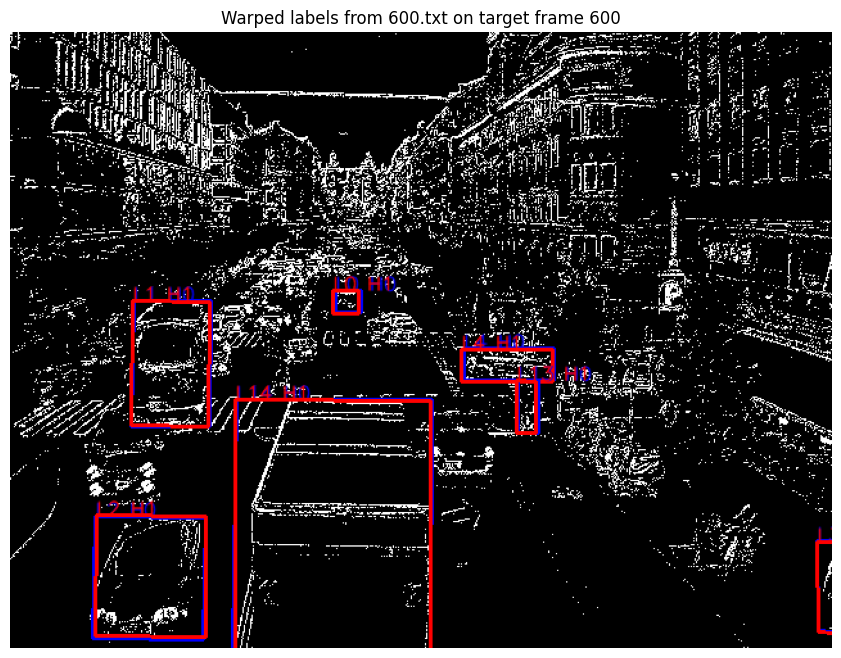

In [103]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

frame_idx = 600
event_frame_idx = 601
conf_thr = 0.6
pad = 10

H2, W2 = spike_dict[event_frame_idx].shape[-2:]
H1, W1 = frames[frame_idx].shape[-2:]

label_path = Path(
    f"//172.16.222.2/tmp/Nora/traffic_flow_data/week_36/box_3/"
    f"2024_09_10_15_50_59_recordings/labels/clip_000/{frame_idx}.txt"
)

target = frames[frame_idx].copy()
target_vis = (target > 0).astype(np.uint8) * 255

vis = cv2.cvtColor(target_vis, cv2.COLOR_GRAY2BGR)

colors = [
    (255, 0, 0),    # H_sel[0] blue in BGR
    (0, 0, 255),    # H_sel[1] red in BGR
    (0, 255, 255),  # extra homographies if any
    (255, 0, 255),
]

def inside_frame(corners_xy, W, H, pad=10):
    xs = corners_xy[:, 0]
    ys = corners_xy[:, 1]
    return (
        (xs >= pad).all() and
        (xs <= W - pad).all() and
        (ys >= pad).all() and
        (ys <= H - pad).all()
    )

for label_idx, s in enumerate(label_path.read_text().splitlines()):
    cls, x, y, w, h, conf = s.split()[:6]
    conf = float(conf)

    if conf <= conf_thr:
        continue

    x, y, w, h = map(float, (x, y, w, h))

    # YOLO normalized label coords are in spike/event-frame coordinates
    x *= W2
    y *= H2
    w *= W2
    h *= H2

    corners = np.float32([
        [x - w / 2, y - h / 2],
        [x + w / 2, y - h / 2],
        [x + w / 2, y + h / 2],
        [x - w / 2, y + h / 2],
    ]).reshape(-1, 1, 2)

    warped_corners = [
        cv2.perspectiveTransform(corners, H).reshape(-1, 2)
        for H in H_top[:2]
    ]

    # Optional: skip labels that are too close to/outside target border
    # if not all(inside_frame(c, W1, H1, pad=pad) for c in warped_corners):
    #    continue

    for h_idx, c in enumerate(warped_corners):
        color = colors[h_idx % len(colors)]

        cv2.polylines(
            vis,
            [np.round(c).astype(np.int32)],
            True,
            color,
            2,
        )

        # label index + homography index
        text_pos = tuple(np.round(c[0]).astype(int))
        cv2.putText(
            vis,
            f"L{label_idx} H{h_idx}",
            text_pos,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            color,
            1,
            cv2.LINE_AA,
        )

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"Warped labels from {label_path.name} on target frame {frame_idx}")
plt.axis("off")
plt.show()

In [ ]:
"\\172.16.222.2\EBVrecordings\2024-TrafficMonitoring\data_collection\week_35/"box3/2024_09_03_16_25_15_recordings

### Test if interpolation needed

In [ ]:
clip_dir = "//172.16.222.2/tmp/Nora/traffic_flow_data/week_31/box_1/2024_07_31_16_54_30_recordings/event_frames"
clip_path= os.path.join(clip_dir, "clip_000_frames.h5")

with h5py.File(clip_path, "r") as f:
    frames = f["frames"][:]

activity = frames.reshape(frames.shape[0], -1).sum(axis=1)

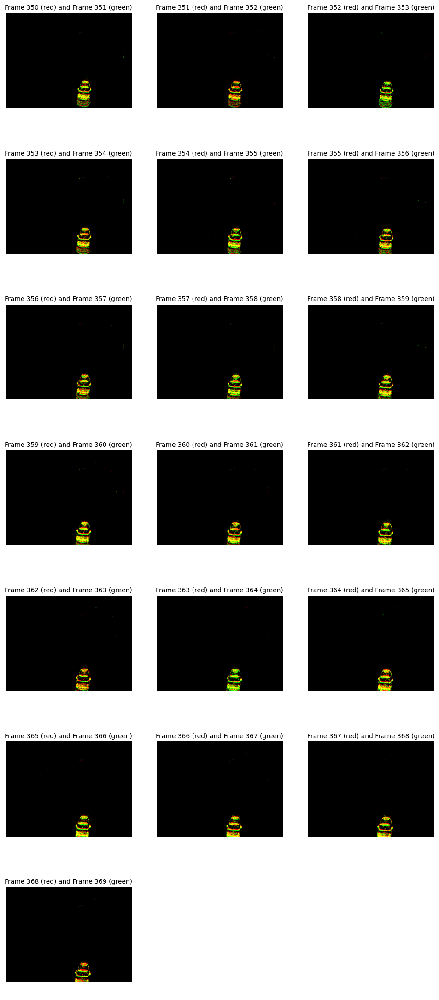

In [ ]:
start = 350
n = 20
cols = 3
n = np.min((21,n))
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))

axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(rows * cols):
    ax = axes[i]

    if i < n - 1:
        idx = start + i

        prev_frame = frames[idx]
        curr_frame = frames[idx + 1]

        rgb = np.zeros((*prev_frame.shape, 3))
        rgb[..., 0] = frames[idx]
        rgb[..., 1] = frames[idx + 1]

        ax.imshow(rgb)
        ax.set_title(f"Frame {idx} (red) and Frame {idx+1} (green)", fontsize=10)

    ax.axis('off')